# 01-具身智能入门与技术架构


## 1. 课程目标与本篇范围

《具身智能实战：AI机械臂从零到一》围绕一台桌面机械臂展开：先建立机械实体，再实现运动控制、环境感知和任务决策，最后学习通过数据训练动作策略。

课程希望完成的系统是一个能够感知环境、理解任务并执行抓取的机械臂智能体。这里的**智能体（Agent）**，指能够获得环境信息、选择动作并与环境交互的系统。

| 课程阶段 | 当前要解决的问题 | 课件列出的主要内容 |
|---|---|---|
| 物理实体 | 怎样让算法影响真实物体？ | 电机选型、驱动与机械结构、URDF、机械臂组装 |
| 运动控制 | 怎样让机械臂准确、平稳地运动？ | 运动学正解与逆解、PID、上位机与遥操作 |
| 环境感知 | 怎样找到目标，知道它在哪里？ | OpenCV、YOLO、神经网络与CNN |
| 认知决策 | 怎样把人的要求变成可执行任务？ | 语音识别与合成、大语言模型、视觉与语言融合 |
| 自主学习 | 怎样从演示或交互数据中学习动作？ | 模仿学习、强化学习、仿真测试与现实部署 |

本篇是十五篇笔记中的第 **01** 篇，主要依据 `具身智能实战01.pptx` 的第 **1—7、10—45页**，按课件顺序整理定义、技术架构、工程挑战、教学案例与研究方向。第46页开始的电机驱动内容留给第02篇。

本篇以PPT为主，保留帮助理解的原图，省略讲师介绍、宣传和重复铺垫。电机参数、运动学公式、环境安装与代码实现将在对应篇章展开。


## 2. 人工智能怎样进入物理世界

课件首先提出一个问题：人工智能已经能够处理语言、图像等数据，接下来怎样参与真实世界中的工作？

它用“计算智能”和“物理智能”说明关注点的变化。

| 关注点 | 计算智能 | 物理智能 |
|---|---|---|
| 主要处理对象 | 文本、图像等数字信息 | 物体、空间、运动及其反馈 |
| 常见结果 | 生成回答、识别图像、给出预测 | 移动物体、完成装配、执行抓取 |
| 输出后的环境变化 | 输出通常仍是数字信息 | 动作会改变物体位置、接触关系或设备状态 |
| 后续判断依据 | 新输入、已有数据或用户反馈 | 传感器获得的实际执行结果 |

例如，模型可以生成“拿起桌上的苹果”这句话，但真实抓取还要确定苹果的位置、计算机械臂怎样到达、控制关节运动，并检查是否抓住。语言中的目标必须通过传感、规划与控制落实到物理动作。

课件将这一方向称为**具身智能（Embodied AI）**：让智能系统通过身体与环境发生交互，并利用交互结果完成任务和学习。


## 3. 机器人学与人工智能怎样结合

课件先区分两类研究的典型重心，再说明它们在具身智能中的结合。

| 领域 | 课件强调的研究重心 | 在机械臂中的作用 |
|---|---|---|
| 机器人学（Robotics） | 精确控制、运动规划、运动学与动力学模型 | 建立关节、连杆和末端运动之间的关系，执行可控的动作 |
| 人工智能（AI） | 从数据中识别模式、进行预测与生成 | 理解图像和语言，从数据中学习感知、决策或动作策略 |
| 具身智能 | 将身体、智能算法与环境交互结合 | 根据实际环境选择动作，并利用执行反馈继续工作 |

这里的区分用于说明研究重心，实际系统可以同时采用模型方法和学习方法。

课件用“机器人学身体＋AI大脑”帮助入门，进一步强调两者需要通过交互形成完整系统。机械结构提供运动能力，算法利用传感器信息判断当前状态，执行机构改变环境，新的环境状态再影响下一次判断。

### 基于模型与基于数据

课件把具身智能描述为 `Model-based + Data-driven` 的结合。

- **基于模型（Model-based）**：利用机械结构、几何关系或物理规律描述系统。例如，根据连杆长度与关节角度计算末端位置。
- **基于数据（Data-driven）**：从样本和交互记录中学习规律。例如，从专家操作数据中学习在不同观察下应该采取什么动作。

两种方法可以分工协作。目标识别可以利用学习模型，末端定位可以利用运动学模型，关节运动则通过反馈控制执行。了解这些分工，才能判断某个问题应该在哪一环解决。


## 4. 核心机制：感知、决策、执行与反馈

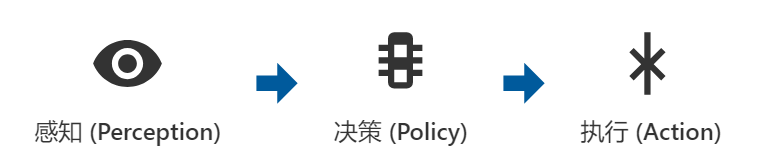

*来源：`具身智能实战01.pptx` 第18页原图。图中展示感知、决策和执行三个环节，执行后的环境反馈使它们形成循环。*

### 4.1 感知：获得当前环境与自身状态

感知（Perception）提供后续判断需要的信息。例如，摄像头提供目标的外观与位置线索，编码器提供关节角度，力或力矩传感器提供接触与受力信息。

对机械臂来说，需要同时了解外部环境和自身状态：既要知道目标在哪里，也要知道机械臂目前处于什么位置。

### 4.2 决策：根据观察和目标选择动作

决策环节回答“下一步做什么”。任务规划可以把较大的要求分成步骤，策略（Policy）则根据当前观察或状态选择动作。

课件原图用 `Policy` 标注决策。策略可以由规则、规划方法或学习模型实现，不应仅凭“决策”二字就认定它一定由大语言模型完成。

### 4.3 执行：让动作实际发生

执行（Action）由机械结构、驱动与控制系统完成。上层给出的任务需要变成机械臂可以执行的运动要求，再落实到关节和电机。

例如，“靠近苹果”是任务描述，“末端到达某个坐标”是运动要求，“各关节转到相应角度”则进一步接近执行层。具体转换将在正解、逆解和控制笔记中学习。

### 4.4 反馈：用实际结果决定后续行为

机械臂执行动作后，物体位置和机械臂状态可能发生变化。传感器再次测量，系统据此判断动作是否完成、目标是否移动、下一步是否需要修正。

**执行结果重新成为决策输入，构成了交互闭环。**这一关系贯穿后续的运动控制、视觉抓取和策略学习。


### 4.5 一次性输出与交互闭环

课件用以下两种流程作对比：

| 流程 | 课件中的表达 | 关键差异 |
|---|---|---|
| 一次性模型输出 | 静态数据、训练、模型、输出 | 这一轮输出本身没有自动接入实际行动结果 |
| 具身交互 | 感知、决策、执行、反馈、新感知 | 后续动作依赖环境实际发生的变化 |

课件强调“实时与闭环”。对机械臂而言，反馈要在任务允许的时间内影响后续动作，否则目标可能已经移动，或者执行状态已经改变。

**补充辨析：**运行时根据新观察调整动作，与训练时更新模型参数是两件事。闭环运行可以使用已经训练好的策略，并不要求机械臂每执行一步就重新训练模型。课件关于“大模型没有形成闭环”的表述，应结合这里的一次性输出示例理解，不作为所有模型系统的统一结论。


## 5. 具身智能的四层技术架构

课件从下到上划分硬件、软件与系统、算法与认知、应用四层。分层帮助我们明确每部分承担的责任，也帮助定位问题。

| 层次 | 主要负责什么 | 课件中的代表内容 |
|---|---|---|
| 硬件层 | 产生动作、获取信号、提供计算能力 | 电机、减速器、传感器、MCU、GPU/NPU |
| 软件／系统层 | 组织设备、模型与数据通信 | ROS/ROS2、RTOS、仿真环境、DDS、WebSocket、gRPC |
| 算法／认知层 | 感知、决策、规划与控制 | OpenCV、YOLO、CLIP、LLM、强化／模仿学习、运动学、PID |
| 应用层 | 定义系统要完成的实际工作 | 分拣、装配、家庭服务、巡检、医疗康复 |

### 5.1 硬件层：身体、传感器与计算平台

硬件层包括三组内容。

| 组成 | 课件列出的设备 | 在系统中的作用 |
|---|---|---|
| 驱动单元 | 电机、减速器、控制器 | 产生并传递运动与力矩 |
| 传感单元 | 摄像头、编码器、力矩传感器 | 测量环境、自身位置及受力状态 |
| 计算平台 | MCU、边缘计算设备、板载GPU/NPU | 执行控制程序与算法计算 |

MCU是微控制器，课件将它与底层控制对应；GPU/NPU等计算单元则为较复杂的模型计算提供条件。它们可以在同一系统中承担不同工作。

课件指出，硬件决定智能体的物理能力上限。机械臂的长度、关节范围、输出能力和传感条件，会限制它能到达哪里、能操作什么，以及能够获得哪些反馈。上层算法需要在这些条件内工作。


### 5.2 软件／系统层：连接硬件与算法

硬件信号、算法输入和动作指令需要通过系统软件组织起来。

| 类别 | 课件列出的技术 | 需要理解的作用 |
|---|---|---|
| 机器人软件与运行环境 | ROS、ROS2 | 组织机器人软件组件、数据交换与相关工具 |
| 实时操作系统 | RTOS | 按时间要求组织嵌入式任务与资源 |
| 仿真与展示环境 | NVIDIA Isaac Sim、MuJoCo、Three.js | 在虚拟环境中表示机器人，并按具体工具能力进行测试或展示 |
| 通信机制 | DDS、WebSocket、gRPC | 在不同组件或设备之间传递状态与指令 |

课件把这一层称为连接硬件与算法的桥梁。它要让传感器数据抵达算法，让算法结果抵达执行系统，并让各部分按照约定的接口交换信息。

**补充辨析：**课件中的 `three3D.js` 按常用库名称整理为 `Three.js`。Three.js主要负责三维图形展示，Isaac Sim和MuJoCo具有不同的仿真能力，不能仅因为它们都展示三维机器人，就把它们视为功能相同的物理仿真器。


### 5.3 算法／认知层：感知、决策与控制

课件在这一层列出三组能力。

| 能力 | 课件中的方法或模型 | 在机械臂任务中回答的问题 |
|---|---|---|
| 感知 | OpenCV、CNN/Transformer、YOLO、CLIP | 环境中有什么，目标在哪里，视觉信息与语言怎样关联？ |
| 决策与规划 | LLM任务规划、PPO、行为克隆BC、Diffusion Policy | 怎样安排任务，当前应该采取什么动作？ |
| 控制 | PID、运动学与动力学相关方法 | 怎样把运动要求落实为准确、平稳的实际动作？ |

其中，CNN是卷积神经网络，YOLO用于目标检测，CLIP用于学习图像与文本的关联。PPO属于强化学习方法，BC是行为克隆，Diffusion Policy是一种学习动作策略的方法。本篇先明确它们的位置，不展开训练与实现。

任务规划与运动控制承担不同尺度的工作。大模型可以参与理解要求和安排步骤，具体末端运动还要满足机械臂结构、关节范围及执行条件。

**补充辨析：**课件在这一层同时提到MCP。MCP（Model Context Protocol，模型上下文协议）用于连接模型与工具等能力，属于接口与调用机制；它本身不计算运动学，也不替代PID控制。阅读技术架构时，应区分“怎样调用能力”和“能力内部怎样求解”。


### 5.4 应用层：系统最终完成什么工作

| 课件中的应用方向 | 任务示例 |
|---|---|
| 工业自动化 | 分拣、装配 |
| 家庭服务 | 清洁、烹饪 |
| 特种作业 | 巡检、救援 |
| 医疗康复 | 外骨骼、护理 |

应用层定义目标，其余各层提供实现目标需要的条件。同样是“抓取”，在教学演示、工业生产和家庭环境中，目标物体、环境变化与执行要求都可能不同。

因此，具身智能是一个需要各层配合的系统工程。感知识别正确，并不自动意味着抓取成功；系统还需要正确的坐标关系、可达的动作、可靠的执行和对结果的判断。


## 6. 具身智能的四类核心挑战

课件将问题概括为：仿真与现实的差异、数据稀疏、泛化，以及安全性与可解释性。

这些问题相互关联。例如，真实交互数据难以大量获取，于是需要仿真；仿真生成的数据又可能与现实不同；系统在训练条件之外执行时，还需要面对泛化和安全问题。

### 6.1 Sim-to-Real Gap：仿真与现实为什么不同

`Sim-to-Real`指将在仿真中开发或学习的能力迁移到真实设备。`Gap`是两者之间的差异。

课件列出摩擦、光照、材质和延迟等因素。仿真只能根据模型和参数近似现实，真实设备与环境还会存在未准确描述的细节。因此，仿真中表现良好的策略，直接放到真实机械臂上可能失效。

课件给出两种思路：

| 思路 | 怎样做 | 解决什么问题 |
|---|---|---|
| 领域随机化（Domain Randomization） | 在仿真中改变光照、颜色或物理参数等条件 | 让模型接触更多变化，减少对单一条件的依赖 |
| 系统辨识（System Identification） | 测量真实设备与环境参数，用于改进模型 | 让仿真更接近实际系统 |

两种方法的侧重点不同：一个增加训练条件的变化，一个提高模型对真实系统的描述准确性。


### 6.2 数据稀疏：机器人为什么难以获得大量数据

机器人获取一次交互数据，需要真实执行动作并测量结果。这个过程消耗时间，也可能造成设备磨损或实验失败。它不像收集静态数字资料那样容易扩展。

课件提出以下方向：

| 方法 | 基本思路 |
|---|---|
| 模仿学习（Imitation Learning） | 从专家演示中学习，减少从零开始的盲目探索 |
| 离线强化学习（Offline RL） | 利用已有交互数据学习策略，提高已有数据的利用率 |
| 数据增强（Data Augmentation） | 对已有数据作适当变换或扩充，增加可用训练样本 |

这里的目标是提高数据效率：尽量从有限记录中获得有效信息，减少昂贵的真实试错。模仿学习与离线强化学习是不同方法，具体区别在第13—14篇展开。


### 6.3 泛化：换物体、换环境后还能否完成任务

泛化（Generalization）指模型面对没有见过的情况时，仍能有效完成任务的能力。

课件指出，模型可能在训练环境中表现很好，但换成新物体、新场景或新任务后，性能明显下降。若每次变化都重新训练一个专用模型，成本会很高。

课件列出两条研究思路：

- **机器人基础模型（Foundation Models）**：用大量、多样的机器人数据预训练，再针对具体任务调整。
- **元学习（Meta-learning）**：学习适应新任务的方法，提高在新条件下调整的效率。

“完成过一次演示”和“能够适应多种条件”代表不同能力。评估系统时，需要关注成功依赖了哪些环境与物体条件。


### 6.4 安全性与可解释性：动作要可控，原因要可追溯

在物理世界中，动作会直接影响设备、物体和人。课件把安全性与可解释性列为实际应用需要解决的问题。

| 概念 | 课件提出的问题 |
|---|---|
| 安全性（Safety） | 在人机交互和复杂环境中，怎样避免伤害或破坏，怎样设定行为边界？ |
| 可解释性（Interpretability） | 为什么做出这个决策？出现问题时，能否回溯和诊断原因？ |

安全性关注行为和结果是否符合约束，可解释性关注决策依据和过程能否被理解。两者相关，但不能互相替代。

这些约束要贯穿感知、决策和执行。既要判断目标与动作是否合理，也要了解实际执行是否满足要求。


## 7. 按完整系统构建过程学习

课件采用“物理实体、运动控制、环境感知、认知决策、自主学习”的递进顺序。前一阶段提供后一阶段需要的条件：先建立可以控制的机械臂，再逐步加入视觉、任务理解与学习能力。

### 7.1 学习阶段与技术层次的对应

学习阶段与四层架构并非一一对应。

硬件阶段同时需要机械结构与建模工具；运动控制阶段同时需要系统通信和控制算法；自主学习则需要数据、训练方法、运行环境以及实际执行设备。课件强调，各阶段是在已有系统上逐步增加能力。

### 7.2 用案例理解公式与算法的作用

课件给出两个教学案例。

| 案例 | 想实现的行为 | 需要串起的知识 |
|---|---|---|
| “指哪打哪” | 用鼠标指定位置，让机械臂指向该位置 | 目标表示、运动学逆解、运动控制 |
| “看到并指向” | 通过摄像头识别桌上的苹果，再让机械臂指向它 | 视觉感知、目标定位、坐标关系、机械臂运动 |

第一个案例先解决“给定目标，怎样运动”，第二个案例再增加“目标怎样从视觉中获得”。这种安排使读者能够观察每一项能力加入后，系统行为发生了什么变化。

课件提到雅可比矩阵、牛顿迭代、YOLO网络和损失函数等理论内容，用案例说明它们服务于什么问题。本篇先理解问题之间的连接，具体公式、参数和代码在后续笔记中学习。


## 8. 跨学科应用与研究方向

### 8.1 与已有课程结合

课件面向计算机、自动化和机械等学科，建议按已有知识基础接入具身智能。

| 学科方向 | 课件给出的结合方式 |
|---|---|
| 计算机 | 开设人工智能实践、ROS等相关课程；把视觉部分作为计算机视觉案例，把大模型规划作为自然语言处理应用 |
| 自动化／机械 | 将硬件搭建、运动学与PID结合机器人学和自动控制原理，再引入强化学习与AI方法 |

这说明具身智能既需要软件与数据方法，也需要机械结构和控制知识。各学科可以从熟悉的模块进入，再理解它与其他模块的关系。

### 8.2 课件列出的研究问题

| 方向 | 可以继续研究的问题 |
|---|---|
| Sim-to-Real | 怎样让仿真模型或策略更适合真实环境？ |
| 多模态数据融合 | 怎样结合视觉、力和语言等不同信息？ |
| LLM任务规划 | 怎样让语言模型理解并规划物理任务？ |
| 数据采集与利用 | 怎样提高机器人交互数据的质量和利用效率？ |

这些方向对应前面已经出现的系统问题。研究对象可以是某个算法，也可以是模块之间的连接方式与整体任务表现。


## 9. 前沿思想：将动作表示为Token

课件最后介绍“万物皆可Token化”（Tokenization of Everything）的思路：把机器人的动作也表示为模型可以处理和预测的符号序列。

Token是模型处理序列时使用的基本单元。语言模型根据已有内容预测后续Token；课件用类似方式说明，机器人模型也可以根据图像、指令等信息预测后续动作表示。

| 课件中的类比 | 输入 | 预测结果示例 |
|---|---|---|
| 语言模型 | “今天天气很好，我们去……” | “散步” |
| 具身模型，课件以RT-2举例 | 桌上有苹果的图像，以及“拿起苹果”的指令 | “机械臂向下移动10cm” |

**补充理解：**课件中的“向下移动10cm”是帮助理解的动作示例。实际动作Token怎样对应关节、末端运动或其他控制量，要由具体模型的表示方法和执行接口决定，不能把示例直接作为真实机械臂的运动参数。

这一思路的重点是，把感知信息、任务要求和动作表示纳入学习过程。课件将其作为通用机器人智能的一种研究方向，与前面基于模型的运动学与控制知识共同构成课程的技术背景。


## 10. 十五篇笔记安排与资料对应

| 编号 | 笔记标题 | 主要对应资料 |
|---|---|---|
| 01 | 具身智能入门与技术架构 | `具身智能实战01.pptx` 第1—7、10—45页 |
| 02 | 机械臂电机原理与选型 | `具身智能实战01.pptx` 第46—76页 |
| 03 | 机械传动与位置反馈 | `具身智能实战01.pptx` 第77—101页 |
| 04 | 数字孪生、仿真与Sim-to-Real | `具身智能实战02.pptx` 第12—37页 |
| 05 | URDF机械臂建模 | `具身智能实战02.pptx` 第38—61页 |
| 06 | 机械臂运动学正解 | `具身智能实现03-运动学正解.pptx` |
| 07 | 机械臂运动学逆解 | `具身智能实战04-运动学逆解.pptx` |
| 08 | 闭环控制与PID | `具身智能-控制论.pptx`、`具身智能-PID.pptx` |
| 09 | 数字图像与OpenCV入门 | `opencv.pptx` 的数字图像、摄像头、ROI和图像坐标内容 |
| 10 | OpenCV识别与目标跟踪 | `opencv.pptx` 的识别、跟踪案例与传统视觉局限 |
| 11 | 视觉定位与简化手眼标定 | `opencv.pptx` 的比例标定、透视变换与姿态测量 |
| 12 | 大模型基础与部署方式 | `大模型介绍.pptx` |
| 13 | 强化学习入门 | `具身智能-强化学习.pptx` |
| 14 | 模仿学习与行为克隆 | `具身智能-模仿学习.pptx` |
| 15 | CNN与视觉特征学习 | `卷积神经网络CNN.pdf`，作为PPT主题的补充 |

`具身智能实战02.pptx` 第1—11页的Git、Conda与Node.js环境说明作为后续相关笔记的附录，不另占篇数。

### 本篇来源对应

| 本篇内容 | `具身智能实战01.pptx` 页码 |
|---|---|
| 课程目标与五阶段概览 | 1—7 |
| 从数字信息到物理交互 | 10—14 |
| 机器人学、AI与具身智能 | 15—17 |
| 交互闭环与反馈 | 18—20 |
| 四层技术架构 | 21—27 |
| 四类核心挑战 | 28—34 |
| 构建顺序与教学案例 | 35—39 |
| 学科融合与研究方向 | 40—41 |
| 动作Token与RT-2类比 | 43—45 |

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。资料路径为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

本篇未转录视频。第42页仅提示观看采访与数据收集视频，没有具体正文，不据此补写案例。文中标明的“补充理解／辨析”用于澄清术语与适用边界。
